# Time Series Forecasting — Complete Assignments

**Original work using reproducible synthetic retail sales:** 96 monthly records, January 2018–December 2025 (fixed seed 2026). Not a real retail dataset. The final 12 months are held out for genuine evaluation.

**Assignment 1:** additive decomposition (trend, seasonality, residuals). **Assignment 2:** ADF and KPSS tests and differencing. **Assignment 3:** ARIMA vs Prophet forecasting with MAE, RMSE, MAPE for both. All figures and numerical outcomes are generated by running the cells.

## Dataset generation and chronological train/test split

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet

warnings.filterwarnings('ignore', category=FutureWarning)
rng = np.random.default_rng(2026)
dates = pd.date_range('2018-01-01', periods=96, freq='MS')
t = np.arange(96)
sales = (820 + 8.2*t + 0.018*t**2 + 145*np.sin(2*np.pi*t/12-np.pi/4)
         + 55*np.cos(4*np.pi*t/12) + np.where(np.isin(dates.month,[10,11]),75,0)
         + rng.normal(0,45,96))
df = pd.DataFrame({'Sales': np.round(np.maximum(100,sales),2)}, index=dates)
df.index.name = 'ds'
train, test = df['Sales'].iloc[:-12], df['Sales'].iloc[-12:]
print('Train:',train.index.min().date(),'through',train.index.max().date(),len(train))
print('Test:',test.index.min().date(),'through',test.index.max().date(),len(test))
print(df.head(8).to_string())
assert len(train)==84 and len(test)==12

Importing plotly failed. Interactive plots will not work.


Train: 2018-01-01 through 2024-12-01 84
Test: 2025-01-01 through 2025-12-01 12
              Sales
ds                 
2018-01-01   736.78
2018-02-01   829.01
2018-03-01   761.17
2018-04-01   955.10
2018-05-01   994.37
2018-06-01  1015.87
2018-07-01  1013.34
2018-08-01   956.98


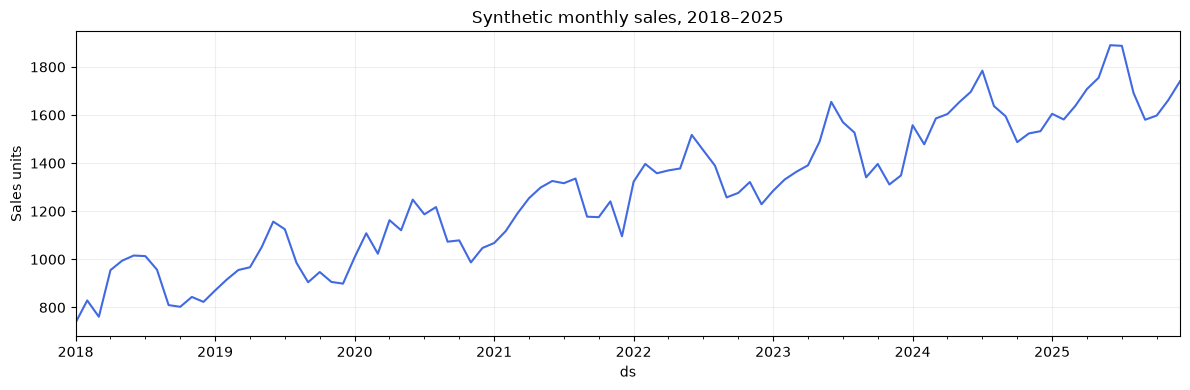

In [2]:
fig,ax=plt.subplots(figsize=(12,4))
df['Sales'].plot(ax=ax, color='royalblue')
ax.set(title='Synthetic monthly sales, 2018–2025',ylabel='Sales units')
ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## Assignment 1: Trend, seasonality and residuals

Additive decomposition: **Observed = Trend + Seasonality + Residual**. Since observations are monthly, `period=12` represents yearly repeating patterns. Decomposition describes historical behavior and is **not** used for fitting holdout forecasts.

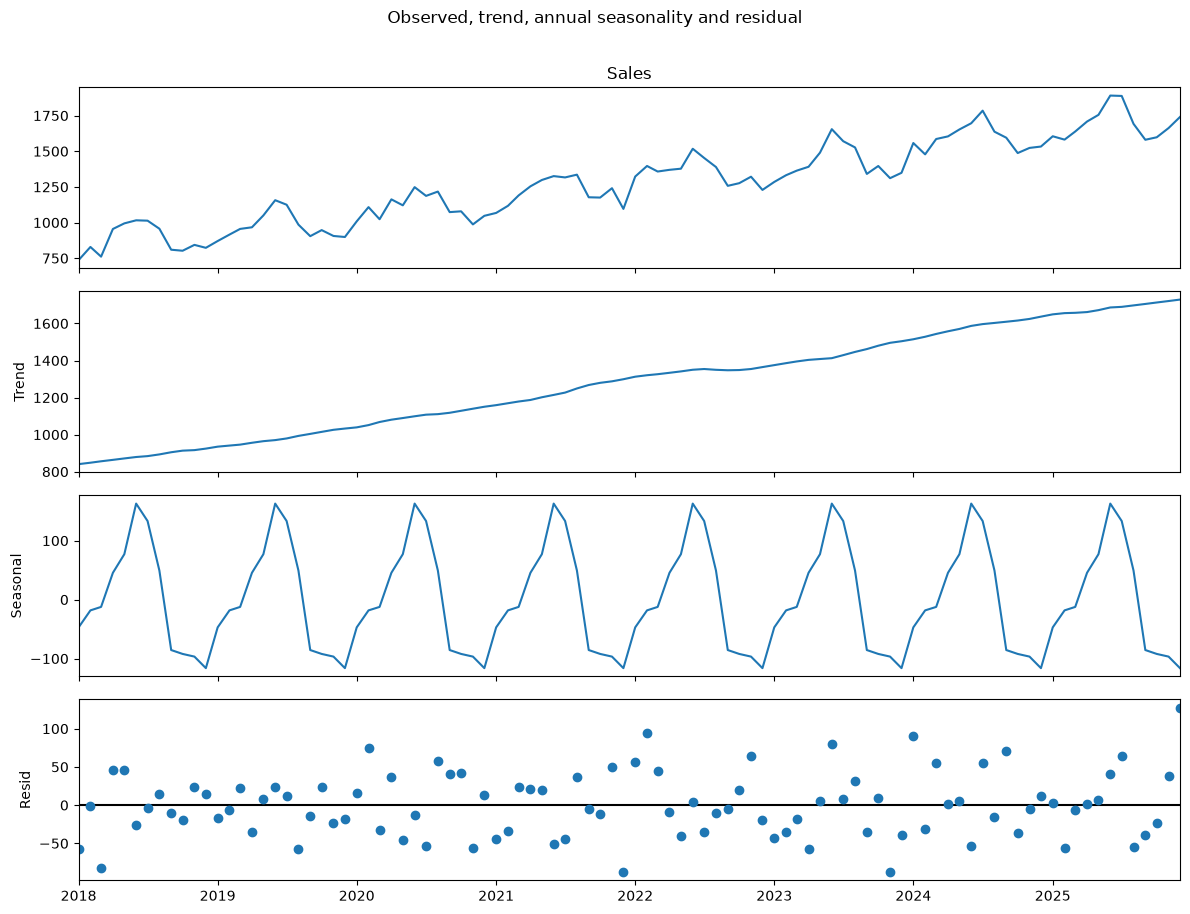

Residual standard deviation: 42.52


In [3]:
decomp=seasonal_decompose(df['Sales'],model='additive',period=12,extrapolate_trend='freq')
fig=decomp.plot()
fig.set_size_inches(12,9)
fig.suptitle('Observed, trend, annual seasonality and residual',y=1.01)
plt.tight_layout(); plt.show()
print('Residual standard deviation:',round(decomp.resid.dropna().std(),2))

**Interpretation:** Trend is the long-run growth component; seasonality repeats each year; residuals contain movements that the two systematic components do not explain.

## Assignment 2: ADF and KPSS stationarity testing

The **ADF** null hypothesis is a unit root; a p-value below 0.05 rejects this null. The **KPSS** null with `regression='c'` is level stationarity; a p-value below 0.05 rejects the stationarity null. Both tests use *training data only*. Results may disagree; neither alone proves stationarity. Differencing removes a changing level, while lag-12 differencing addresses yearly seasonal patterns.

In [4]:
def stationarity_test(series,name):
    x=series.dropna()
    a=adfuller(x,autolag='AIC')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        k=kpss(x,regression='c',nlags='auto')
    return {'Series':name,'ADF p':a[1],'KPSS p':k[1],
            'ADF rejects unit root':a[1]<.05,
            'KPSS rejects stationarity':k[1]<.05}
stationarity=pd.DataFrame([
    stationarity_test(train,'Raw training data'),
    stationarity_test(train.diff(),'First difference'),
    stationarity_test(train.diff(12),'Annual seasonal difference'),
    stationarity_test(train.diff().diff(12),'First + seasonal difference')])
print(stationarity.to_string(index=False,float_format=lambda x:f'{x:.4f}'))

                     Series  ADF p  KPSS p  ADF rejects unit root  KPSS rejects stationarity
          Raw training data 0.9900  0.0100                  False                       True
           First difference 0.0000  0.1000                   True                      False
 Annual seasonal difference 0.0001  0.1000                   True                      False
First + seasonal difference 0.1908  0.1000                  False                      False


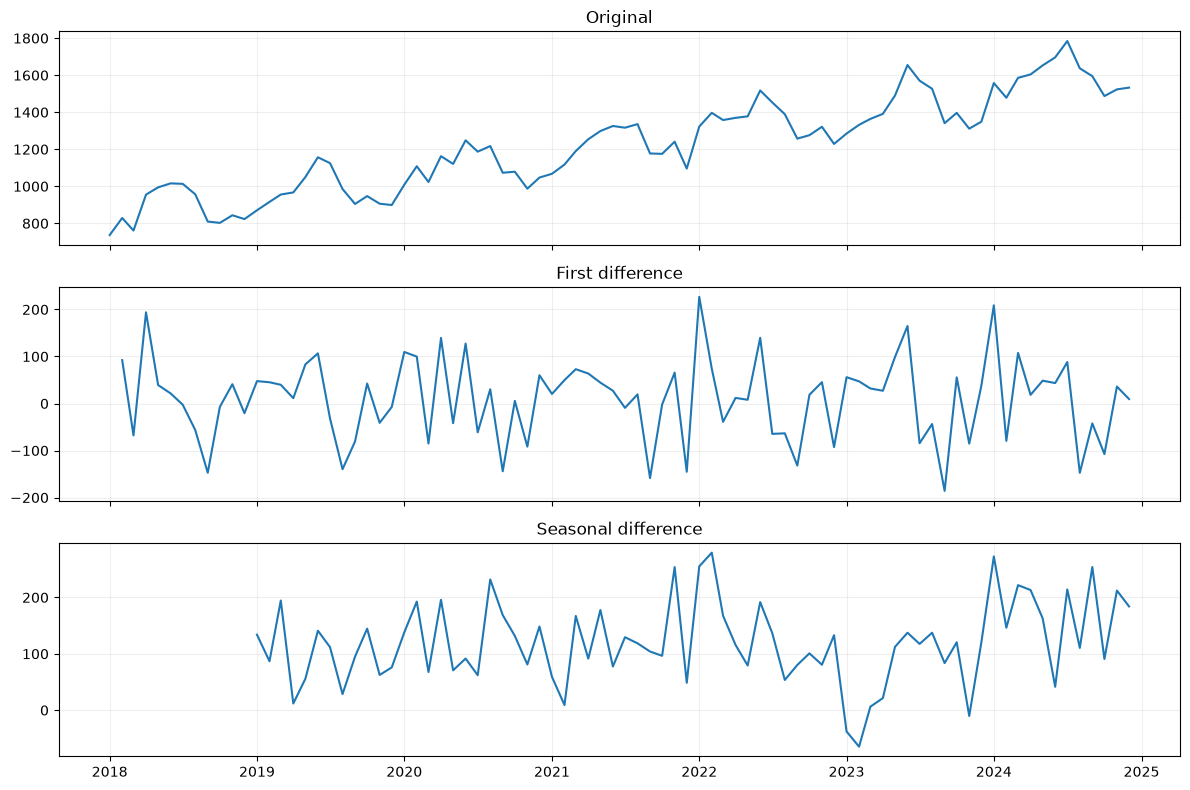

In [5]:
fig,axes=plt.subplots(3,1,figsize=(12,8),sharex=True)
for ax,(title,s) in zip(axes,[('Original',train),('First difference',train.diff()),('Seasonal difference',train.diff(12))]):
    ax.plot(s); ax.set_title(title); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## Assignment 3: ARIMA and Prophet models

A strict chronological **84-month training / 12-month test** split was already created. No test values are supplied to either estimator when fitting or selecting parameters.

### ARIMA
ARIMA(p,d,q): `p` is autoregressive lag order, `d` is differencing degree and `q` is moving-average error lag order. ACF and PACF inform candidate choices. A small grid of orders is ranked by **training-only AIC**. Plain ARIMA has no explicit seasonal terms, which is a limitation on this annual-seasonal dataset.

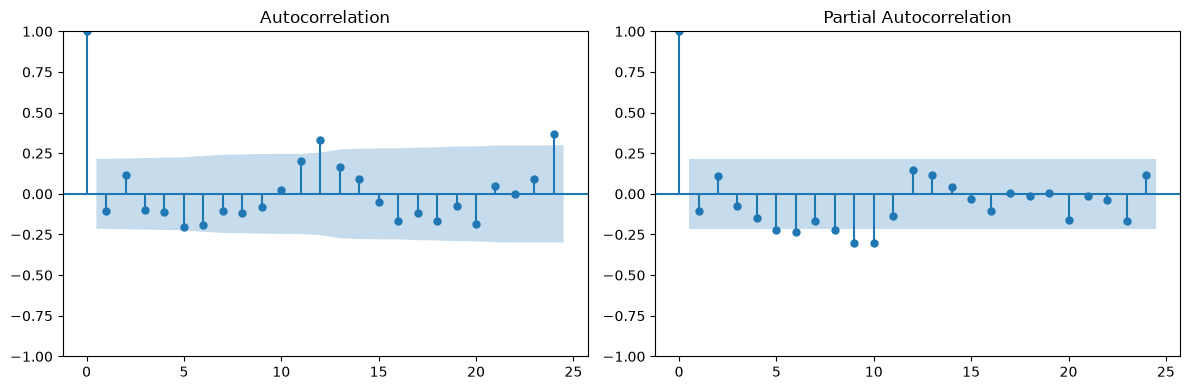

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
plot_acf(train.diff().dropna(),lags=24,ax=axes[0])
plot_pacf(train.diff().dropna(),lags=24,ax=axes[1],method='ywm')
plt.tight_layout(); plt.show()

In [7]:
scores=[]
for p,d,q in product(range(3),[0,1,2],range(3)):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            fit=ARIMA(train,order=(p,d,q),enforce_stationarity=False,enforce_invertibility=False).fit()
        if np.isfinite(fit.aic): scores.append(((p,d,q),float(fit.aic)))
    except Exception: pass
scores.sort(key=lambda item:item[1])
best_order=scores[0][0]
print('Top ARIMA orders (train AIC):',scores[:5])
print('Chosen ARIMA order:',best_order)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    arima_model=ARIMA(train,order=best_order,enforce_stationarity=False,enforce_invertibility=False).fit()
arima_pred=pd.Series(np.asarray(arima_model.forecast(steps=len(test))),index=test.index,name='ARIMA')

Top ARIMA orders (train AIC): [((0, 2, 2), 936.4223261775296), ((1, 2, 2), 937.3852451248437), ((2, 2, 2), 939.0924667372633), ((0, 1, 2), 942.5660681219429), ((1, 1, 2), 943.2929610164547)]
Chosen ARIMA order: (0, 2, 2)


### Prophet

Prophet represents sales as a trend plus additive seasonal components and residual variation. For monthly observations, yearly seasonality is enabled while daily and weekly seasonality are disabled. It is fitted only to the same training set.

In [8]:
p_train=train.reset_index()
p_train.columns=['ds','y']
p_model=Prophet(yearly_seasonality=True,weekly_seasonality=False,
                daily_seasonality=False,seasonality_mode='additive',changepoint_prior_scale=0.1)
p_model.fit(p_train)
p_fc=p_model.predict(pd.DataFrame({'ds':test.index}))
prophet_pred=pd.Series(p_fc['yhat'].to_numpy(),index=test.index,name='Prophet')
print(p_fc[['ds','yhat','yhat_lower','yhat_upper']].round(2).to_string(index=False))

/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
07:55:47 - cmdstanpy - INFO - Chain [1] start processing


07:55:48 - cmdstanpy - INFO - Chain [1] done processing


        ds    yhat  yhat_lower  yhat_upper
2025-01-01 1577.31     1527.12     1623.24
2025-02-01 1664.78     1618.22     1710.76
2025-03-01 1680.83     1633.25     1727.59
2025-04-01 1756.71     1711.88     1801.64
2025-05-01 1782.91     1736.45     1830.30
2025-06-01 1863.81     1816.72     1909.98
2025-07-01 1854.84     1808.80     1905.00
2025-08-01 1807.10     1758.66     1854.81
2025-09-01 1688.01     1639.52     1736.09
2025-10-01 1672.84     1624.98     1722.85
2025-11-01 1677.24     1633.39     1724.97
2025-12-01 1659.30     1610.76     1709.18


### Proper evaluation of **both** models

**MAE** = average absolute forecast error (units). **RMSE** = root mean squared forecast error (units), more sensitive to large misses. **MAPE** = average absolute percentage error; actual sales are strictly positive in this dataset. Lower values indicate better performance. Both methods are tested on *exactly the same months*.

In [9]:
def evaluate(actual,predicted):
    a=np.asarray(actual,dtype=float); p=np.asarray(predicted,dtype=float)
    assert a.shape==p.shape and np.all(a!=0)
    return {'MAE':mean_absolute_error(a,p),
            'RMSE':np.sqrt(mean_squared_error(a,p)),
            'MAPE (%)':100*np.mean(np.abs((a-p)/a))}
metrics=pd.DataFrame({'ARIMA':evaluate(test,arima_pred),
                      'Prophet':evaluate(test,prophet_pred)}).T
print('HELD-OUT FORECAST ERRORS:')
print(metrics.round(3).to_string())
print('\nBest MAE:',metrics['MAE'].idxmin())
print('Best RMSE:',metrics['RMSE'].idxmin())
print('Best MAPE:',metrics['MAPE (%)'].idxmin())
assert metrics.shape==(2,3) and np.isfinite(metrics.to_numpy()).all()

HELD-OUT FORECAST ERRORS:
             MAE     RMSE  MAPE (%)
ARIMA    114.580  148.606     6.471
Prophet   56.833   65.536     3.413

Best MAE: Prophet
Best RMSE: Prophet
Best MAPE: Prophet


Predictions on held-out 2025 months:
             Actual    ARIMA  Prophet
ds                                   
2025-01-01  1605.07  1541.51  1577.31
2025-02-01  1581.50  1550.15  1664.78
2025-03-01  1638.47  1558.78  1680.83
2025-04-01  1708.35  1567.41  1756.71
2025-05-01  1755.13  1576.05  1782.91
2025-06-01  1890.42  1584.68  1863.81
2025-07-01  1887.79  1593.31  1854.84
2025-08-01  1692.22  1601.95  1807.10
2025-09-01  1580.49  1610.58  1688.01
2025-10-01  1598.08  1619.21  1672.84
2025-11-01  1662.57  1627.84  1677.24
2025-12-01  1740.38  1636.48  1659.30


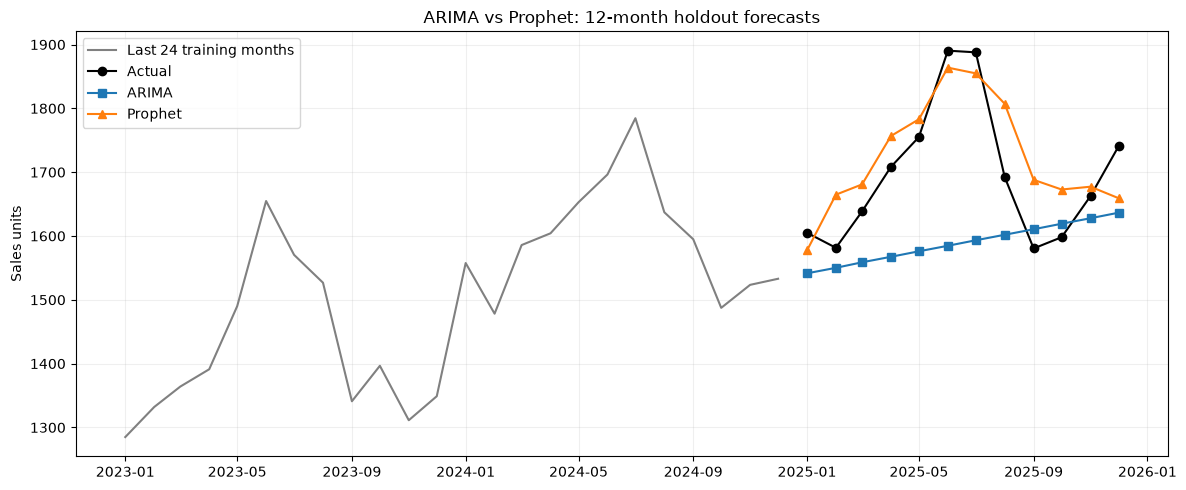

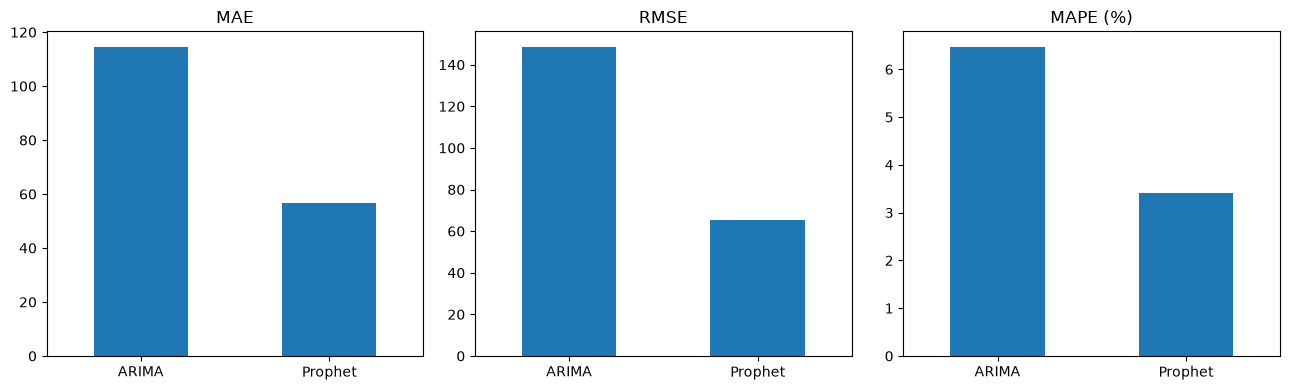

In [10]:
forecast_table=pd.DataFrame({'Actual':test,'ARIMA':arima_pred,'Prophet':prophet_pred})
print('Predictions on held-out 2025 months:')
print(forecast_table.round(2).to_string())
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(train.index[-24:],train.iloc[-24:],label='Last 24 training months',color='gray')
ax.plot(test.index,test,marker='o',label='Actual',color='black')
ax.plot(test.index,arima_pred,marker='s',label='ARIMA')
ax.plot(test.index,prophet_pred,marker='^',label='Prophet')
ax.set(title='ARIMA vs Prophet: 12-month holdout forecasts',ylabel='Sales units')
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,col in zip(axs,metrics.columns):
    metrics[col].plot.bar(ax=ax)
    ax.set(title=col,xlabel='')
    ax.tick_params(axis='x',rotation=0)
plt.tight_layout();plt.show()

## Conclusion and next steps

The comparison table identifies the winning model **separately by MAE, RMSE and MAPE**; inspect these executed results rather than assuming a winner. Yearly seasonality is present in the synthetic data, and unseasonal ARIMA is not necessarily optimal. For production quality, compare seasonal naive or SARIMA baselines and use rolling-origin backtesting.

**Reproduce:** `pip install -r requirements.txt` on Python 3.11 and run all cells. The GitHub Actions workflow automatically executes and saves outputs.